### Classify Yelp reviews + amazon reviews + imdb reviews into two polarity, positive or negative.


In [20]:
!pip install wordcloud

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import kagglehub
import os
import shutil

# Download latest version
path = kagglehub.dataset_download("rahulin05/sentiment-labelled-sentences-data-set")

print("Path to dataset files:", path)

drive_path = "/content/sentiment-data"
os.makedirs(drive_path, exist_ok=True)

shutil.copytree(path, drive_path, dirs_exist_ok=True)

print("Dataset saved to:", drive_path)

Path to dataset files: /kaggle/input/sentiment-labelled-sentences-data-set
Dataset saved to: /content/sentiment-data


#### Basic text preprocessing
Before we actually do classification, let's review on stopwords removal and lemmatization, which is a common procedure in preprocessing the text before we input into our classifier.

Note: If you are using Deep Leaning models like BERT, Transformers or other pre-trained huggingface stuffs, usuallly preprocessing IS NOT required, since they need all the context words to learn. Preprocessing(stop word removal, lemmatization, and so on) may actually harm the model!!

Here we use SVM model. So, lets perform Preprocessing.

##### Lemmatization

Lemmatization is an essential step in text preprocessing for NLP. It deals with the structural or morphological analysis of words and break-down of words into their base forms or "lemmas".

For Eg - The words walk, walking, walks, walked are indicative towards a common activity i.e. walk. And since they have different spelling structure, it makes it a confusing task for our algorithms to treat them differently. So, these will be treated under a single lemma.

Note: But if you use very powerful neural network like transformer, NO NEED lemmatization....

In [4]:
import spacy

nlp = spacy.load("en_core_web_sm")

doc = nlp("running run ran")

for token in doc:
    print(token.text, token.lemma_)

running run
run run
ran run


In [5]:
doc = nlp("Going to eat at Thammasat with my / best good friends.")

for token in doc:
    print(token.text, token.lemma_)

Going go
to to
eat eat
at at
Thammasat Thammasat
with with
my my
/ /
best good
good good
friends friend
. .


##### Stopwords

Stopwords are common words that we wanna remove, such as "of", "until", etc.  Removing them helps model memorize only the keywords.

Note: In powerful network, we DON'T remove stop words

In [6]:
import spacy
from spacy.lang.en.stop_words import STOP_WORDS

stop_words = list(STOP_WORDS)
print(len(stop_words))

nlp = spacy.load("en_core_web_sm")
doc = nlp("Chaky is going to Disney Land to eat with his best friend Peter.")

clean_text = []
for token in doc:
    if token.text not in stop_words:
        clean_text.append(token.text)

clean_text

326


['Chaky', 'going', 'Disney', 'Land', 'eat', 'best', 'friend', 'Peter', '.']

##### Removing punctuation
You notice if we were to insert the token into some classifier, it may not be necessary to input the punctuations like full stops, apostropy and so on. Thus we can also consider removing punctuation, using POS taggers of spacy.

In [8]:
import spacy

nlp = spacy.load("en_core_web_sm")
doc = nlp("Going to eat at Thammasat with my / best      good friends.")

for token in doc:
    print(token.text, token.pos_)  #notice PUNCT and SPACE


Going VERB
to PART
eat VERB
at ADP
Thammasat PROPN
with ADP
my PRON
/ SYM
best ADJ
      SPACE
good ADJ
friends NOUN
. PUNCT


To get the full list of possible POS tags

In [12]:
print(nlp.get_pipe("parser").labels)

('ROOT', 'acl', 'acomp', 'advcl', 'advmod', 'agent', 'amod', 'appos', 'attr', 'aux', 'auxpass', 'case', 'cc', 'ccomp', 'compound', 'conj', 'csubj', 'csubjpass', 'dative', 'dep', 'det', 'dobj', 'expl', 'intj', 'mark', 'meta', 'neg', 'nmod', 'npadvmod', 'nsubj', 'nsubjpass', 'nummod', 'oprd', 'parataxis', 'pcomp', 'pobj', 'poss', 'preconj', 'predet', 'prep', 'prt', 'punct', 'quantmod', 'relcl', 'xcomp')


To remove punctuation is quite easy as well

In [15]:
import spacy

nlp = spacy.load("en_core_web_sm")
doc = nlp("Going to eat at Thammasat with my / best      good friends.")

token_no_punct = []
for token in doc:
    if token.pos_ != "PUNCT" and token.pos_ != "SPACE" and token.pos_ != "SYM":
        token_no_punct.append(token.text)

token_no_punct

['Going',
 'to',
 'eat',
 'at',
 'Thammasat',
 'with',
 'my',
 'best',
 'good',
 'friends']

##### Removing spaces and lowercasing

Last thing we wanna worry is removing unwanted spaces using strip() and lowercasing using .lower()

We shall also combine other techniques we learned so far....

In [16]:
import spacy

nlp = spacy.load("en_core_web_sm")
doc = nlp("Going to eat at Thammasat with my / best      good friends.")

stripped_lowercase_token = []
for token in doc:
        stripped_lowercase_token.append(token.text.lower().strip())

stripped_lowercase_token

['going',
 'to',
 'eat',
 'at',
 'thammasat',
 'with',
 'my',
 '/',
 'best',
 '',
 'good',
 'friends',
 '.']

#### Combine everything
Let's combine everything into one nice function

In [17]:
import spacy
from spacy.lang.en.stop_words import STOP_WORDS

nlp = spacy.load("en_core_web_sm")
stopwords = list(STOP_WORDS)

def preprocessing(sentence):
    doc = nlp(sentence)
    cleaned_tokens = []
    for token in doc:
        if token.text not in stopwords and token.pos_ not in ["PUNCT", "SYM", "SPACE"]:
            cleaned_tokens.append(token.lemma_.lower().strip())
    return cleaned_tokens

In [18]:
# Test
preprocessing("Going to eat at Thammasat with my best      good friends.")

['go', 'eat', 'thammasat', 'good', 'good', 'friend']

In [19]:
preprocessing("We are having a lot of fun.")

['we', 'have', 'lot', 'fun']

### Sentiment Analysis

Let's do sentiment analysis with the help sklearn, pandas and spacy!!!

For simplicity, we use count vectorizer and tf idf transformer. And we use Linear SVM Classifier

In [22]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, TfidfTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import wordcloud

data_yelp = pd.read_csv("/content/sentiment-data/yelp_labelled.txt", sep="\t", header=None, names=["Reviews", "Sentiment"])
data_amazon = pd.read_csv("/content/sentiment-data/amazon_cells_labelled.txt", sep="\t", header=None, names=["Reviews", "Sentiment"])
data_imdb = pd.read_csv("/content/sentiment-data/imdb_labelled.txt", sep="\t", header=None, names=["Reviews", "Sentiment"])

In [23]:
data_yelp.head()

,Reviews,Sentiment
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1


In [24]:
data_amazon.head()

,Reviews,Sentiment
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


In [26]:
data_imdb.shape, data_yelp.shape, data_amazon.shape

((748, 2), (1000, 2), (1000, 2))

In [25]:
data_imdb.head()

,Reviews,Sentiment
0,"A very, very, very slow-moving, aimless movie ...",0
1,Not sure who was more lost - the flat characte...,0
2,Attempting artiness with black & white and cle...,0
3,Very little music or anything to speak of.,0
4,The best scene in the movie was when Gerardo i...,1


In [27]:
# combine all the reviews
data = pd.concat([data_amazon, data_yelp, data_imdb], ignore_index=True)
data.shape

(2748, 2)

### EDA

In [29]:
# Lets display the counts of postive and negative reviews to check class imbalances. (if there's class imbalance, use SMOTE under/over sampling INSIDE the cross validation loop)
data["Sentiment"].value_counts()

,count
Sentiment,
1,1386
0,1362


In [30]:
data.isnull().sum()

,0
Reviews,0
Sentiment,0


#### Countvectorizer to find out frequent positive and negative words

By doing this, we can see that derive many useful stuffs.

In [34]:
countvectorizer = CountVectorizer(tokenizer=preprocessing)  # preprocessing refers to the function we wrote earlier, the input should be a bunch of text, the output should return tokens

# test corpus
corpus = [
    'Chaky is coding python',
    'Deep learning is fun',
    'Spacy is cool and fun',
    'please hashtag #spacy'
]

result = countvectorizer.fit_transform(corpus)

print(result.toarray(), result.toarray().shape)  # (no of docs, tokens in vocab), each value is the count of token in the vocab => doc token count matrix

print(countvectorizer.get_feature_names_out())

[[1 1 0 0 0 0 0 1 0]
 [0 0 0 1 1 0 1 0 0]
 [0 0 1 0 1 0 0 0 1]
 [0 0 0 0 0 1 0 0 1]] (4, 9)
['chaky' 'code' 'cool' 'deep' 'fun' 'hashtag' 'learning' 'python' 'spacy']


/usr/local/lib/python3.11/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


In [59]:
# Lets generate count vectors for postive and negative reviews separately - We try to see top words, categorized by positive and negative sentiments here

countvectorizer = CountVectorizer(tokenizer=preprocessing)

pos_df = data[data.Sentiment == 1]
neg_df = data[data.Sentiment == 0]

print(pos_df.shape, neg_df.shape)

# Each row represents a review and each column represets a word in the vocabulary and each value represetns count of that word in the review.
pos_result = countvectorizer.fit_transform(pos_df["Reviews"])  # positive reviews doc-term matrix
pos_vocabs = countvectorizer.get_feature_names_out()  # gives you the unique list of tokens learned from the positive reviews.

neg_result = countvectorizer.fit_transform(neg_df["Reviews"])  # negative reviews doc-term matrix
neg_vocabs = countvectorizer.get_feature_names_out()  # gives you the unique list of tokens learned from the negative reviews.

print(pos_result.toarray().shape)
print(neg_result.toarray().shape)
print(pos_vocabs.shape, neg_vocabs.shape)

(1386, 2) (1362, 2)


/usr/local/lib/python3.11/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


(1386, 2711)
(1362, 2687)
(2711,) (2687,)


(1, 2711) (1, 2687)
(1, 2711)
(2711, 1)
(2711, 1)
         0
good   230
great  194
film   103
movie  103
phone   92
work    84
love    74
like    73
place   63
food    60
(2687, 1)


<Axes: title={'center': 'Top 10 Negative Tokens'}>

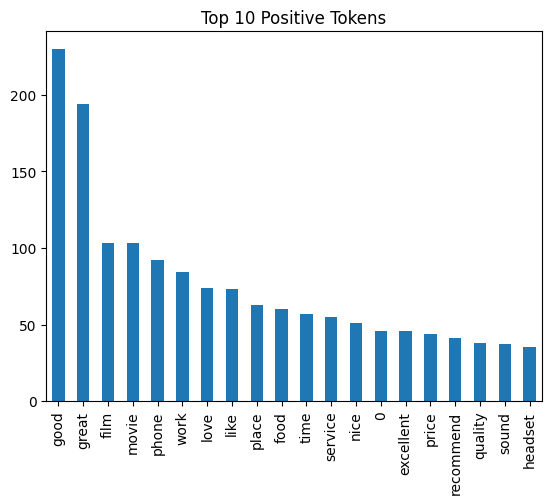

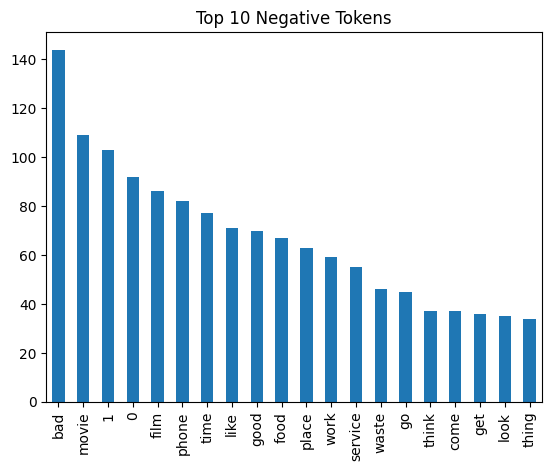

In [60]:
import numpy as np


# Sum word counts across all documents(reviews here)
pos_counts = np.sum(pos_result, axis=0)
neg_counts = np.sum(neg_result, axis=0)

# neg_counts and pos_counts are the total frequencies of each word across all reviews. The result is a 1 x vocab_size sparse matrix.

print(pos_counts.shape, neg_counts.shape)

# Create sorted frequency DataFrame
pos_freq_df = pd.DataFrame(pos_counts, columns=pos_vocabs)
print(pos_freq_df.shape)

pos_freq_df = pos_freq_df.T
print(pos_freq_df.shape)
# print(pos_freq_df.head())

pos_freq_df = pos_freq_df.sort_values(by=0, ascending=False)
print(pos_freq_df.shape)
print(pos_freq_df.head(10))

# similarly do for negative counts
neg_freq_df = pd.DataFrame(neg_counts, columns=neg_vocabs).T.sort_values(by=0, ascending=False)
print(neg_freq_df.shape)

# Plot
pos_freq_df.head(20).plot(kind="bar", legend=False, title="Top 10 Positive Tokens")
neg_freq_df.head(20).plot(kind="bar", legend=False, title="Top 10 Negative Tokens")

Let’s break this final line down:

➤ pd.DataFrame(pos_counts, columns=pos_vocabs)

We create a 1-row DataFrame where:
- Columns = tokens
- Values = frequency of each token

➤ .T

Transpose so that:
- Index = token
- Column = frequency (named 0 by default)

➤ .sort_values(by=0, ascending=False)

Sort tokens in descending order by their count.

Result:

A DataFrame showing the most frequent words in positive reviews, sorted from most to least.

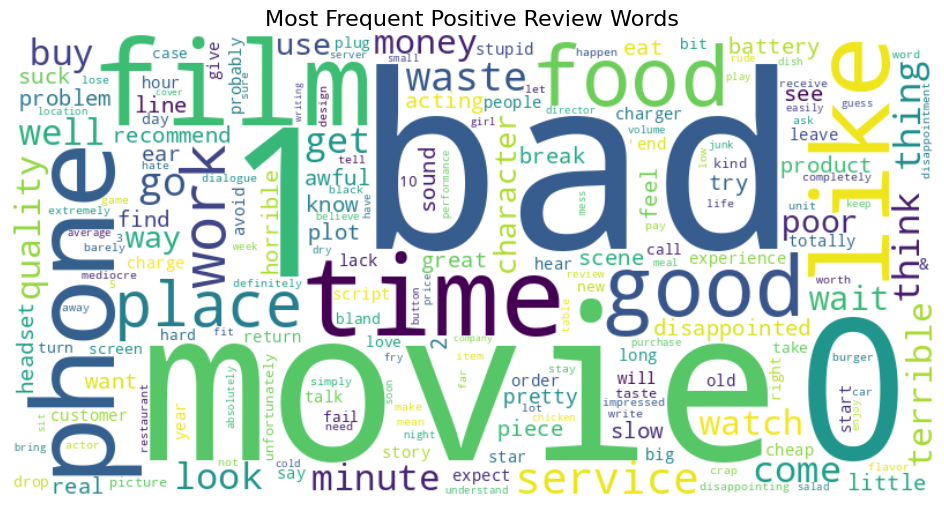

In [57]:
# Visualize using wordcloud
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Convert DataFrame to dictionary: {word: count}

word_freq_dict = pos_freq_df[0].to_dict()

wordcloud = WordCloud(width=800, height=400, background_color="white", colormap="viridis").generate_from_frequencies(word_freq_dict)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Most Frequent Positive Review Words", fontsize=16)
plt.show()

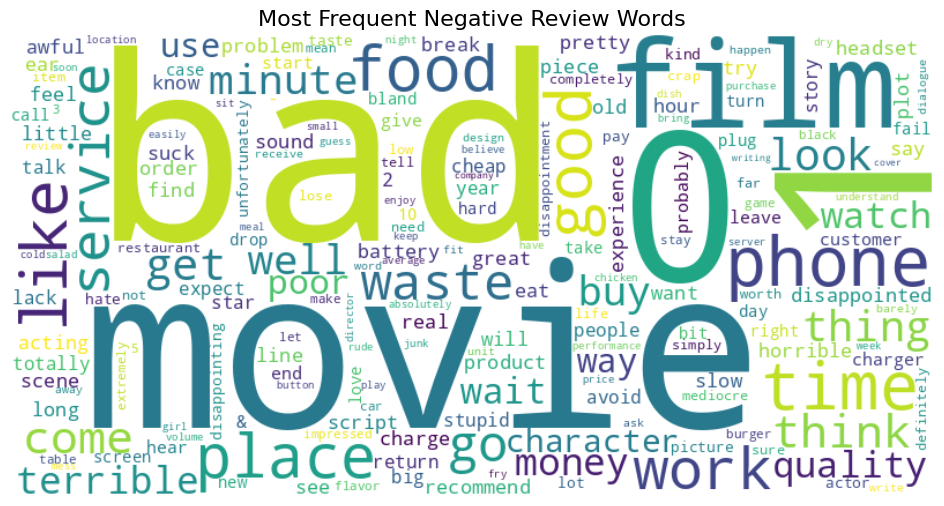

In [61]:
from wordcloud import WordCloud

word_freq_dict = neg_freq_df[0].to_dict()

wordcloud = WordCloud(width=800, height=400, background_color="white", colormap="viridis").generate_from_frequencies(word_freq_dict)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Most Frequent Negative Review Words", fontsize=16)
plt.show()

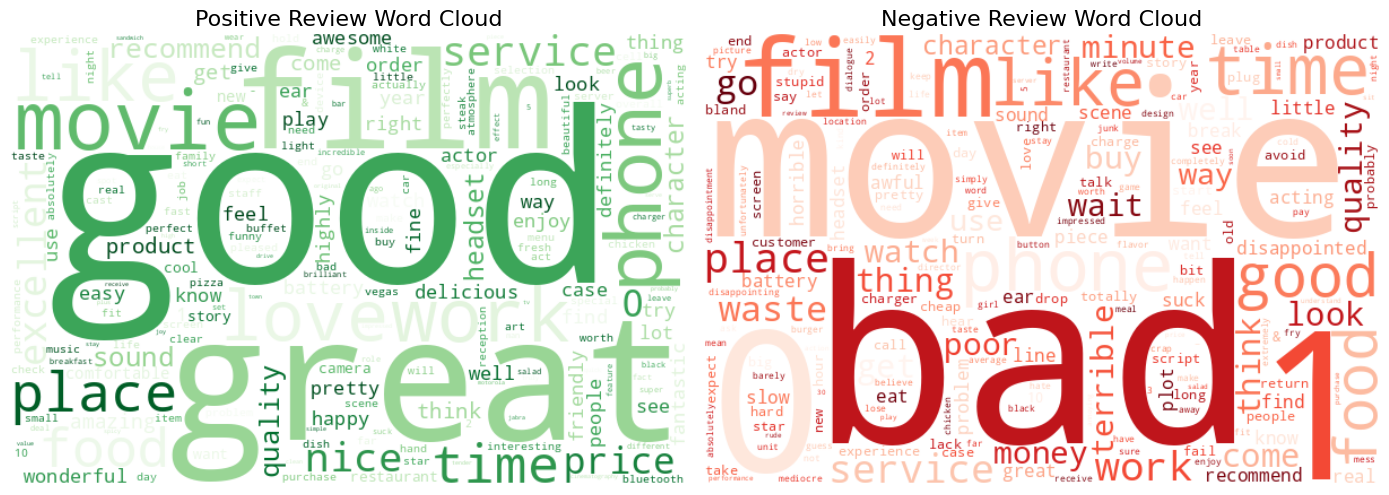

In [62]:
# Visualize Positive vs. Negative Word Clouds

from wordcloud import WordCloud
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Convert to flat arrays
pos_counts_flatten = np.array(pos_counts).flatten()  # (1, 2711) (1, 2687) => (2711,) (2687,)
neg_counts_flatten = np.array(neg_counts).flatten()

# Create frequency dictionaries
pos_freq = dict(zip(pos_vocabs, pos_counts_flatten))  # pos_vocabs: (2711,) neg_vocabs: (2687,)
neg_freq = dict(zip(neg_vocabs, neg_counts_flatten))

# Generate WordClouds
pos_wc = WordCloud(width=600, height=400, background_color='white', colormap='Greens').generate_from_frequencies(pos_freq)
neg_wc = WordCloud(width=600, height=400, background_color='white', colormap='Reds').generate_from_frequencies(neg_freq)

# Plot them side by side
plt.figure(figsize=(14, 7))

# Positive reviews
plt.subplot(1, 2, 1)
plt.imshow(pos_wc, interpolation='bilinear')
plt.axis('off')
plt.title("Positive Review Word Cloud", fontsize=16)

# Negative reviews
plt.subplot(1, 2, 2)
plt.imshow(neg_wc, interpolation='bilinear')
plt.axis('off')
plt.title("Negative Review Word Cloud", fontsize=16)

plt.tight_layout()

#### TfidfVectorizer

TfidVectorizer go beyond one more step, i.e., after counting the number of words, we shall perform a normalization using TF-IDF which focuses on cutting very frequent words which tend to be less meaningful information like "the", "a", "is".

- usually, in NLP, we don't use countvectorizer
- because it makes very frequent words a prominent feature, which we don't want to
- we want something like normalized(countvectorizer) ==> tfidvectorizer

In [63]:
from sklearn.feature_extraction.text import TfidfTransformer  # not vectorize but transformer and it requires frequency features already

# imagine that we already have a frequency features.  We can perform normalization as a follow up
counts = [[3, 0, 1],
          [2, 1, 0],
          [3, 2, 5]]
tfidftransformer = TfidfTransformer()
tfidftransformer.fit_transform(counts).toarray()

array([[0.91892665, 0.        , 0.39442846],
       [0.84080197, 0.54134281, 0.        ],
       [0.39706158, 0.34085938, 0.85214845]])

Note: We used TfidfTransformer. We can also use TfidfVectorizer which automatically accepts raw data (i.e., text data)

In [65]:
# note that it already count for you internally in tfidvectorizer

tfidvec = TfidfVectorizer(tokenizer=preprocessing)

# counts
neg_result = tfidvec.fit_transform(neg_df.Reviews)
neg_vocabs = tfidvec.get_feature_names_out()
pos_result = tfidvec.fit_transform(pos_df.Reviews)
pos_vocabs = tfidvec.get_feature_names_out()

# sum of words across all documents - word freq
neg_counts = np.sum(neg_result, axis=0)
pos_counts = np.sum(pos_result, axis=0)

print(neg_counts.shape, pos_counts.shape)
print(neg_vocabs.shape, pos_vocabs.shape)

/usr/local/lib/python3.11/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


(1, 2687) (1, 2711)
(2687,) (2711,)


In [67]:
# top ten positive terms
df = pd.DataFrame(pos_counts, columns=pos_vocabs).T.sort_values(by=0, ascending=False)
df.head(10)

,0
great,58.703963
good,57.943720
phone,32.194987
work,30.730819
love,25.877770
place,23.558875
film,22.985003
movie,22.843287
food,22.777766
service,22.215604


In [68]:
# top ten negative terms
df = pd.DataFrame(neg_counts, columns=neg_vocabs).T.sort_values(by=0, ascending=False)
df.head(10)

,0
bad,39.281651
phone,23.271888
service,22.415464
time,22.177253
food,21.588159
movie,21.053127
place,19.891297
work,19.683007
good,19.393069
waste,18.572754


As you can see, tf-idf works much better than countvectorizer! Also, a lesson learned is that if we can give very good features to the classifier, the model can work well right away

### Modeling

In [70]:
# Classifier
classifier = LinearSVC()

# vectorizer
tfdif = TfidfVectorizer()

# Data
X = data["Reviews"]
y = data["Sentiment"]

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

# Pipeline
clf = Pipeline([("tfidf", tfdif), ("clf", classifier)])

# Train
clf.fit(X_train, y_train)

# Test
y_pred = clf.predict(X_test)

# Metrics
print(classification_report(y_test, y_pred))

# Confusion Matrix
confusion_matrix(y_test, y_pred)


(2198,) (550,)
              precision    recall  f1-score   support

           0       0.86      0.83      0.84       286
           1       0.82      0.86      0.84       264

    accuracy                           0.84       550
   macro avg       0.84      0.84      0.84       550
weighted avg       0.84      0.84      0.84       550



array([[237,  49],
       [ 38, 226]])

### Real world inference

In [75]:
clf.predict(["Wow, this is amazing analysis"])

array([1])

In [72]:
clf.predict(["Worth of watching it. Please like it"])

array([1])

In [73]:
clf.predict(["Wow, this model sucks"])

array([0])

In [74]:
clf.predict(["This is not bad"])  # Failed in double negative!!! a very useful test... :-)

# possible way to fix this is to get "spanning" features....not single token but multi word tokens

array([0])